In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = '/content/food_nutrition_dataset (2).csv'
df = pd.read_csv(file_path)

# Display basic information
print("--- Dataset Summary ---")
display(df.info())

print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Missing Values ---")
print(df.isnull().sum())

--- Dataset Summary ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 416 entries, 0 to 415
Data columns (total 40 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   food_id                    416 non-null    object 
 1   food_name                  416 non-null    object 
 2   brand                      416 non-null    object 
 3   category                   416 non-null    object 
 4   state                      416 non-null    object 
 5   unit_basis                 416 non-null    object 
 6   calories_kcal              416 non-null    float64
 7   protein_g                  416 non-null    float64
 8   carbs_g                    416 non-null    float64
 9   fat_g                      416 non-null    float64
 10  saturated_fat_g            390 non-null    float64
 11  fiber_g                    396 non-null    float64
 12  sugar_g                    385 non-null    float64
 13  cholesterol_mg            

None


--- First 5 Rows ---


,food_id,food_name,brand,category,state,unit_basis,calories_kcal,protein_g,carbs_g,fat_g,...,caffeine_per_serving_mg,vegetarian,vegan,gluten_free,contains_dairy,contains_egg,contains_nuts,halal_note,meal_type,data_confidence
0,F001,"Chicken breast, skinless",generic,Poultry,raw,per 100 g,120.0,22.5,0.0,2.6,...,0.0,no,no,yes,no,no,no,halal only if halal-slaughtered,lunch;dinner,"typical (USDA-based, rounded)"
1,F002,"Chicken breast, skinless",generic,Poultry,cooked,per 100 g,165.0,31.0,0.0,3.6,...,0.0,no,no,yes,no,no,no,halal only if halal-slaughtered,lunch;dinner,"typical (USDA-based, rounded)"
2,F003,"Chicken thigh, skinless",generic,Poultry,cooked,per 100 g,209.0,26.0,0.0,10.9,...,0.0,no,no,yes,no,no,no,halal only if halal-slaughtered,lunch;dinner,"typical (USDA-based, rounded)"
3,F004,"Chicken drumstick, skinless",generic,Poultry,cooked,per 100 g,172.0,28.3,0.0,5.7,...,0.0,no,no,yes,no,no,no,halal only if halal-slaughtered,lunch;dinner,"typical (USDA-based, rounded)"
4,F005,"Chicken, whole roasted with skin",generic,Poultry,cooked,per 100 g,239.0,27.0,0.0,13.6,...,0.0,no,no,yes,no,no,no,halal only if halal-slaughtered,lunch;dinner,"typical (USDA-based, rounded)"



--- Missing Values ---
food_id                        0
food_name                      0
brand                          0
category                       0
state                          0
unit_basis                     0
calories_kcal                  0
protein_g                      0
carbs_g                        0
fat_g                          0
saturated_fat_g               26
fiber_g                       20
sugar_g                       31
cholesterol_mg               109
sodium_mg                     98
potassium_mg                 171
calcium_mg                   172
iron_mg                      182
magnesium_mg                 184
zinc_mg                      184
vitamin_a_mcg                216
vitamin_c_mg                 216
vitamin_b12_mcg              304
vitamin_d_mcg                307
caffeine_mg                    0
serving_size_g_or_ml           0
serving_description            0
calories_per_serving_kcal      0
fat_per_serving_g              0
sugar_per_serving_g

Plotting distribution of 'category'...


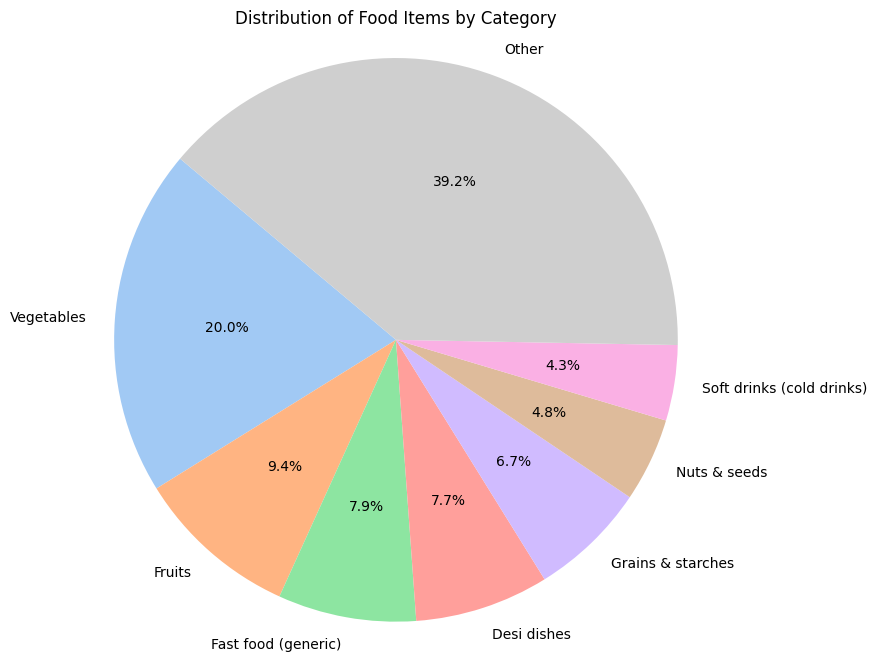

In [3]:
# Using 'category' as a meaningful categorical column for the pie chart
target_col = 'category'
print(f"Plotting distribution of '{target_col}'...")

# Get value counts of the top categories
counts = df[target_col].value_counts()
if len(counts) > 8:
    top_counts = counts.head(7)
    other_count = pd.Series([counts.iloc[7:].sum()], index=['Other'])
    plot_data = pd.concat([top_counts, other_count])
else:
    plot_data = counts

# Plotting the Pie Chart
plt.figure(figsize=(8, 8))
plt.pie(plot_data, labels=plot_data.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title(f'Distribution of Food Items by {target_col.capitalize()}')
plt.axis('equal')
plt.show()

### Machine Learning with Decision Tree Classifier
We will preprocess the nutrition dataset, split it into 80% training and 20% testing sets, and train a Decision Tree model to classify the food items into their respective `category` labels based on their nutritional properties.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder
import pandas as pd
import numpy as np

# Define feature columns (numerical nutrition values) and the target
numerical_features = [
    'calories_kcal', 'protein_g', 'carbs_g', 'fat_g', 'saturated_fat_g',
    'fiber_g', 'sugar_g', 'caffeine_mg', 'serving_size_g_or_ml'
]
target_col = 'category'

# Prepare features and target, handling missing values in feature columns
X_full = df[numerical_features].copy()
for col in X_full.columns:
    X_full[col] = X_full[col].fillna(X_full[col].median())

y_full = df[target_col]

# Identify and filter out classes with only 1 member to allow stratified split
class_counts = y_full.value_counts()
valid_classes = class_counts[class_counts >= 2].index

mask = y_full.isin(valid_classes)
X_filtered = X_full[mask]
y_filtered = y_full[mask]

# Encode target labels into integers
le = LabelEncoder()
y_encoded = le.fit_transform(y_filtered)

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X_filtered, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

# Initialize and train Decision Tree model
clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(X_train, y_train)

# Make predictions
y_pred = clf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))

Model Accuracy: 53.01%

Classification Report:
                           precision    recall  f1-score   support

                Beverages       0.33      0.33      0.33         3
                    Dairy       0.25      0.25      0.25         4
              Desi dishes       0.75      0.50      0.60         6
        Desserts & bakery       0.00      0.00      0.00         1
                     Eggs       0.00      0.00      0.00         1
            Energy drinks       0.00      0.00      0.00         1
      Fast food (branded)       0.00      0.00      0.00         2
      Fast food (generic)       0.56      0.71      0.62         7
                   Fruits       0.67      1.00      0.80         8
        Grains & starches       0.28      0.83      0.42         6
                  Legumes       0.00      0.00      0.00         3
             Nuts & seeds       1.00      0.75      0.86         4
              Oils & fats       0.50      0.50      0.50         2
              

### Model Improvement: Random Forest Classifier
We will replace the single Decision Tree with an ensemble **Random Forest Classifier** and apply **StandardScaler** to normalize the numerical input ranges.

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize and train a Random Forest Classifier
rf_clf = RandomForestClassifier(n_estimators=150, max_depth=10, random_state=42, class_weight='balanced')
rf_clf.fit(X_train_scaled, y_train)

# Make predictions
y_pred_rf = rf_clf.predict(X_test_scaled)

# Evaluate the updated model
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Improved Model (Random Forest) Accuracy: {accuracy_rf * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_rf, target_names=le.classes_, zero_division=0))

Improved Model (Random Forest) Accuracy: 78.31%

Classification Report:
                           precision    recall  f1-score   support

                Beverages       1.00      0.67      0.80         3
                    Dairy       0.67      0.50      0.57         4
              Desi dishes       0.83      0.83      0.83         6
        Desserts & bakery       1.00      1.00      1.00         1
                     Eggs       0.00      0.00      0.00         1
            Energy drinks       0.50      1.00      0.67         1
      Fast food (branded)       0.67      1.00      0.80         2
      Fast food (generic)       0.71      0.71      0.71         7
                   Fruits       0.80      1.00      0.89         8
        Grains & starches       0.86      1.00      0.92         6
                  Legumes       0.67      0.67      0.67         3
             Nuts & seeds       1.00      1.00      1.00         4
              Oils & fats       0.67      1.00      0.80

### Extreme Gradient Boosting (XGBoost) for Maximum Accuracy
We will now train an **XGBoost Classifier**, which iteratively minimizes classification errors using gradient boosting, to see if we can achieve an even higher prediction accuracy.

In [7]:
from xgboost import XGBClassifier

# Initialize the XGBoost Classifier with tuned hyperparameters
xgb_clf = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='mlogloss'
)

# Fit the model on our standardized training data
xgb_clf.fit(X_train_scaled, y_train)

# Make predictions
y_pred_xgb = xgb_clf.predict(X_test_scaled)

# Evaluate the XGBoost model
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
print(f"XGBoost Classifier Accuracy: {accuracy_xgb * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_xgb, target_names=le.classes_, zero_division=0))

XGBoost Classifier Accuracy: 73.49%

Classification Report:
                           precision    recall  f1-score   support

                Beverages       1.00      1.00      1.00         3
                    Dairy       0.67      0.50      0.57         4
              Desi dishes       0.71      0.83      0.77         6
        Desserts & bakery       1.00      1.00      1.00         1
                     Eggs       0.00      0.00      0.00         1
            Energy drinks       1.00      1.00      1.00         1
      Fast food (branded)       0.67      1.00      0.80         2
      Fast food (generic)       0.60      0.43      0.50         7
                   Fruits       0.73      1.00      0.84         8
        Grains & starches       0.83      0.83      0.83         6
                  Legumes       0.67      0.67      0.67         3
             Nuts & seeds       0.80      1.00      0.89         4
              Oils & fats       0.67      1.00      0.80         2
 

### Hyperparameter Tuning on Random Forest using Grid Search
We will now use `GridSearchCV` to explore optimal configurations for `n_estimators`, `max_depth`, and `min_samples_split` in our Random Forest model to achieve peak performance.

In [8]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid to search
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 15, None],
    'min_samples_split': [2, 5],
    'class_weight': ['balanced', 'balanced_subsample']
}

# Initialize Grid Search with 3-Fold Cross Validation
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=3,
    n_jobs=-1,
    scoring='accuracy'
)

# Fit the grid search on the scaled training data
grid_search.fit(X_train_scaled, y_train)

# Get the best estimator
best_rf = grid_search.best_estimator_

# Make predictions with optimized model
y_pred_opt = best_rf.predict(X_test_scaled)

# Evaluate the fine-tuned model
accuracy_opt = accuracy_score(y_test, y_pred_opt)
print(f"Optimized Random Forest Accuracy: {accuracy_opt * 100:.2f}%")
print(f"Best Parameters: {grid_search.best_params_}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_opt, target_names=le.classes_, zero_division=0))

Optimized Random Forest Accuracy: 78.31%
Best Parameters: {'class_weight': 'balanced', 'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 300}

Classification Report:
                           precision    recall  f1-score   support

                Beverages       1.00      0.67      0.80         3
                    Dairy       0.67      0.50      0.57         4
              Desi dishes       0.71      0.83      0.77         6
        Desserts & bakery       1.00      1.00      1.00         1
                     Eggs       0.00      0.00      0.00         1
            Energy drinks       0.50      1.00      0.67         1
      Fast food (branded)       1.00      1.00      1.00         2
      Fast food (generic)       0.71      0.71      0.71         7
                   Fruits       0.80      1.00      0.89         8
        Grains & starches       0.86      1.00      0.92         6
                  Legumes       0.67      0.67      0.67         3
             Nuts & se

### Ensembling Models: Voting Classifier
To push the accuracy even further, we will build a **Voting Classifier** that combines the strengths of our Random Forest, an Extra Trees Classifier, and an XGBoost model.

In [9]:
from sklearn.ensemble import VotingClassifier, ExtraTreesClassifier

# Initialize individual models
rf_best = RandomForestClassifier(n_estimators=200, max_depth=15, random_state=42, class_weight='balanced')
et_best = ExtraTreesClassifier(n_estimators=200, max_depth=15, random_state=42, class_weight='balanced')
xgb_best = XGBClassifier(n_estimators=150, max_depth=5, learning_rate=0.1, random_state=42, eval_metric='mlogloss')

# Combine them into a Soft Voting Classifier
voting_clf = VotingClassifier(
    estimators=[
        ('rf', rf_best),
        ('et', et_best),
        ('xgb', xgb_best)
    ],
    voting='soft'
)

# Train the Voting Classifier
voting_clf.fit(X_train_scaled, y_train)

# Predict and evaluate
y_pred_vote = voting_clf.predict(X_test_scaled)
accuracy_vote = accuracy_score(y_test, y_pred_vote)
print(f"Voting Classifier Accuracy: {accuracy_vote * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_vote, target_names=le.classes_, zero_division=0))

Voting Classifier Accuracy: 74.70%

Classification Report:
                           precision    recall  f1-score   support

                Beverages       1.00      0.67      0.80         3
                    Dairy       0.67      0.50      0.57         4
              Desi dishes       0.71      0.83      0.77         6
        Desserts & bakery       1.00      1.00      1.00         1
                     Eggs       0.00      0.00      0.00         1
            Energy drinks       0.50      1.00      0.67         1
      Fast food (branded)       0.50      1.00      0.67         2
      Fast food (generic)       0.60      0.43      0.50         7
                   Fruits       0.73      1.00      0.84         8
        Grains & starches       0.86      1.00      0.92         6
                  Legumes       0.67      0.67      0.67         3
             Nuts & seeds       1.00      1.00      1.00         4
              Oils & fats       0.67      1.00      0.80         2
  

### Saving the Best Model and Preprocessing Artifacts
We will save the optimized Random Forest model (`best_rf`), the scaler (`scaler`), and the label encoder (`le`) to disk so they can be easily reloaded for future predictions.

In [11]:
import joblib

# Save the model, scaler, and label encoder
joblib.dump(best_rf, 'best_random_forest_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(le, 'label_encoder.pkl')

print("Artifacts saved successfully:")
print("- best_random_forest_model.pkl (Optimized Random Forest Model)")
print("- scaler.pkl (StandardScaler)")
print("- label_encoder.pkl (LabelEncoder)")

Artifacts saved successfully:
- best_random_forest_model.pkl (Optimized Random Forest Model)
- scaler.pkl (StandardScaler)
- label_encoder.pkl (LabelEncoder)
